# Semiconductor Production Yield — Fail Detection (SECOM)

## 1 · Problem framing

**Who has the problem?** The quality engineering team of a semiconductor factory. Every production run is monitored by 590 sensors before it reaches the final line test (Pass / Fail).

**What decision does the model support?** Score every run after production: runs with high fail-risk are sent for early inspection, and engineers get the list of sensors linked to failures.

**Target:** `label` — 1 = Fail, 0 = Pass.

**Metric:** Fails are rare (~7%), so accuracy is misleading — predicting "always Pass" already gives ~93%.
- Missing a failing run is more expensive than inspecting a good one → we care most about **recall on the Fail class**.
- Model selection metric: **PR-AUC**, because it focuses on how well the model ranks the rare fails.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("pandas", pd.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__)

pandas 3.1.0 | numpy 2.5.4 | sklearn 1.9.1


In [2]:
from pathlib import Path
from urllib.request import urlopen
import zipfile, io

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

if not list(DATA_DIR.rglob("secom.data")):
    url = "https://archive.ics.uci.edu/static/public/179/secom.zip"
    with urlopen(url) as r:
        zipfile.ZipFile(io.BytesIO(r.read())).extractall(DATA_DIR)

print([p.name for p in DATA_DIR.rglob("*")])

['secom.data', 'secom.names', 'secom_labels.data']


In [3]:
# Reading files
SENSOR_COLS = [f"sensor_{i:03d}" for i in range(1, 591)]
data_file   = next(DATA_DIR.rglob("secom.data"))
labels_file = next(DATA_DIR.rglob("secom_labels.data"))

X = pd.read_csv(data_file, sep=r"\s+", header=None, names=SENSOR_COLS)

labels = pd.read_csv(labels_file, sep=" ", header=None,
                     names=["raw_label", "timestamp"], quotechar='"')
labels["timestamp"] = pd.to_datetime(labels["timestamp"].str.strip(),
                                     format="%d/%m/%Y %H:%M:%S")
y = (labels["raw_label"] == 1).astype(int)   # 1 = Fail , 0 = Pass

print("X:", X.shape, "| y:", y.shape)
print(y.value_counts())
X.iloc[:5, :8]

X: (1567, 590) | y: (1567,)
raw_label
0    1463
1     104
Name: count, dtype: int64


,sensor_001,sensor_002,sensor_003,sensor_004,sensor_005,sensor_006,sensor_007,sensor_008
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235


## 2 · Data understanding

**Source:** SECOM dataset — UCI Machine Learning Repository (McCann & Johnston, 2008). Real data from a semiconductor manufacturing process.

| Column | Type | Meaning |
|---|---|---|
| `timestamp` | datetime | Date and time of the test |
| `label` | int (0/1) | Line test result: **1 = Fail**, 0 = Pass |
| `sensor_001` … `sensor_590` | float | Sensor measurements (names hidden by the company), may contain missing values |

In [4]:
df = pd.concat([labels["timestamp"], y.rename("label"), X], axis=1)
print("df:", df.shape)
df.head()

df: (1567, 592)


,timestamp,label,sensor_001,sensor_002,sensor_003,sensor_004,sensor_005,sensor_006,sensor_007,sensor_008,...,sensor_581,sensor_582,sensor_583,sensor_584,sensor_585,sensor_586,sensor_587,sensor_588,sensor_589,sensor_590
0,2008-07-19 11:55:00,0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,2008-07-19 12:32:00,0,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,2008-07-19 13:17:00,1,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,2008-07-19 14:43:00,0,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,2008-07-19 15:22:00,0,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432


In [5]:
sensor_dict = pd.DataFrame({
    "dtype":     X.dtypes.astype(str),
    "missing_%": (X.isna().mean() * 100).round(2),
    "n_unique":  X.nunique(),
    "mean":      X.mean().round(3),
    "std":       X.std().round(3),
    "min":       X.min(),
    "max":       X.max(),
})
sensor_dict.sort_values("missing_%", ascending=False).head(10)

,dtype,missing_%,n_unique,mean,std,min,max
sensor_293,float64,91.19,92,0.014,0.011,0.0041,0.0831
sensor_294,float64,91.19,138,335.551,137.692,82.3233,879.2260
sensor_159,float64,91.19,138,1039.651,406.849,234.0996,2505.2998
sensor_158,float64,91.19,128,0.047,0.040,0.0118,0.2876
sensor_493,float64,85.58,226,8.171,1.759,4.8882,21.0443
sensor_086,float64,85.58,97,0.113,0.003,0.1053,0.1184
sensor_359,float64,85.58,20,0.002,0.000,0.0017,0.0047
sensor_221,float64,85.58,69,0.009,0.002,0.0057,0.0240
sensor_245,float64,64.96,66,0.006,0.085,0.0003,1.9844
sensor_518,float64,64.96,543,1.739,4.891,0.2880,113.2758


In [6]:
print("Data types:", X.dtypes.value_counts().to_dict())
print("Time range:", df["timestamp"].min(), "→", df["timestamp"].max())
print(f"Missing cells: {X.isna().sum().sum():,} ({X.isna().mean().mean():.1%} of all values)")
print("Sensors with any missing:", (sensor_dict["missing_%"] > 0).sum())
print("Sensors with > 50% missing:", (sensor_dict["missing_%"] > 50).sum())
print("Constant sensors (1 unique value):", (sensor_dict["n_unique"] <= 1).sum())
print("Duplicate rows:", X.duplicated().sum())

Data types: {dtype('float64'): 590}
Time range: 2008-07-19 11:55:00 → 2008-10-17 06:07:00
Missing cells: 41,951 (4.5% of all values)
Sensors with any missing: 538
Sensors with > 50% missing: 28
Constant sensors (1 unique value): 116
Duplicate rows: 0


In [7]:
counts = y.value_counts()
print(f"Pass: {counts[0]} | Fail: {counts[1]} | Fail rate: {y.mean():.2%}")
print(f"Imbalance ratio ≈ 1 : {counts[0] / counts[1]:.0f}")
print(f"Accuracy of a model that always says 'Pass': {1 - y.mean():.2%}")

Pass: 1463 | Fail: 104 | Fail rate: 6.64%
Imbalance ratio ≈ 1 : 14
Accuracy of a model that always says 'Pass': 93.36%


## 3 · Train / test split — before anything else

We hold out **20% of the runs as a test set** that is never used until the final evaluation.
The split is **stratified**, so both sets keep the same fail rate (~6.6%).
All later decisions (EDA, preprocessing, model choice, tuning, threshold) use the **training set only** — this prevents data leakage.

In [8]:
from sklearn.model_selection import train_test_split

SEED = 42

X_train, X_test, y_train, y_test, t_train, t_test = train_test_split(
    X, y, df["timestamp"],
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)

print(f"Train: {X_train.shape} | fails = {y_train.sum()} ({y_train.mean():.2%})")
print(f"Test:  {X_test.shape}  | fails = {y_test.sum()} ({y_test.mean():.2%})")

Train: (1253, 590) | fails = 83 (6.62%)
Test:  (314, 590)  | fails = 21 (6.69%)


## 4 · Exploratory data analysis (training set only)

### 4.1 Univariate analysis

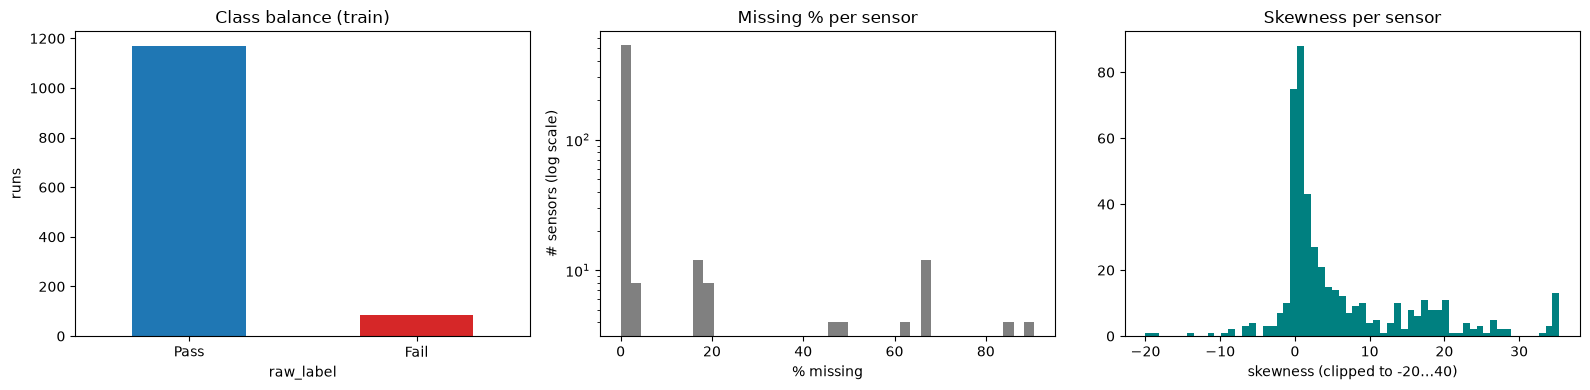

In [9]:
tr = X_train.copy()
miss = tr.isna().mean() * 100
skew = tr.skew()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1) Class balance
y_train.map({0: "Pass", 1: "Fail"}).value_counts().plot.bar(
    ax=axes[0], color=["#1f77b4", "#d62728"])
axes[0].set_title("Class balance (train)")
axes[0].set_ylabel("runs")
axes[0].tick_params(axis="x", rotation=0)

# 2) Missing % per sensor
axes[1].hist(miss, bins=40, color="grey")
axes[1].set_yscale("log")
axes[1].set_title("Missing % per sensor")
axes[1].set_xlabel("% missing")
axes[1].set_ylabel("# sensors (log scale)")

# 3) Skewness per sensor
axes[2].hist(skew.dropna().clip(-20, 40), bins=60, color="teal")
axes[2].set_title("Skewness per sensor")
axes[2].set_xlabel("skewness (clipped to -20…40)")

plt.tight_layout()
plt.show()

In [10]:
q1, q3 = tr.quantile(0.25), tr.quantile(0.75)
iqr = (q3 - q1).replace(0, np.nan)

extreme = (tr < q1 - 3 * iqr) | (tr > q3 + 3 * iqr)
outlier_share = extreme.mean()

print(f"Sensors with |skew| > 2: {(skew.abs() > 2).sum()} of {skew.notna().sum()}")
print(f"Sensors where > 1% of runs are extreme outliers: {(outlier_share > 0.01).sum()}")

Sensors with |skew| > 2: 262 of 474
Sensors where > 1% of runs are extreme outliers: 150


### 4.2 Bivariate analysis — what separates Pass from Fail?

Top 8 sensors by |effect size| (Fail vs Pass):
sensor_104    0.692
sensor_511    0.577
sensor_060    0.504
sensor_349    0.442
sensor_130    0.434
sensor_432    0.424
sensor_065    0.417
sensor_022    0.399


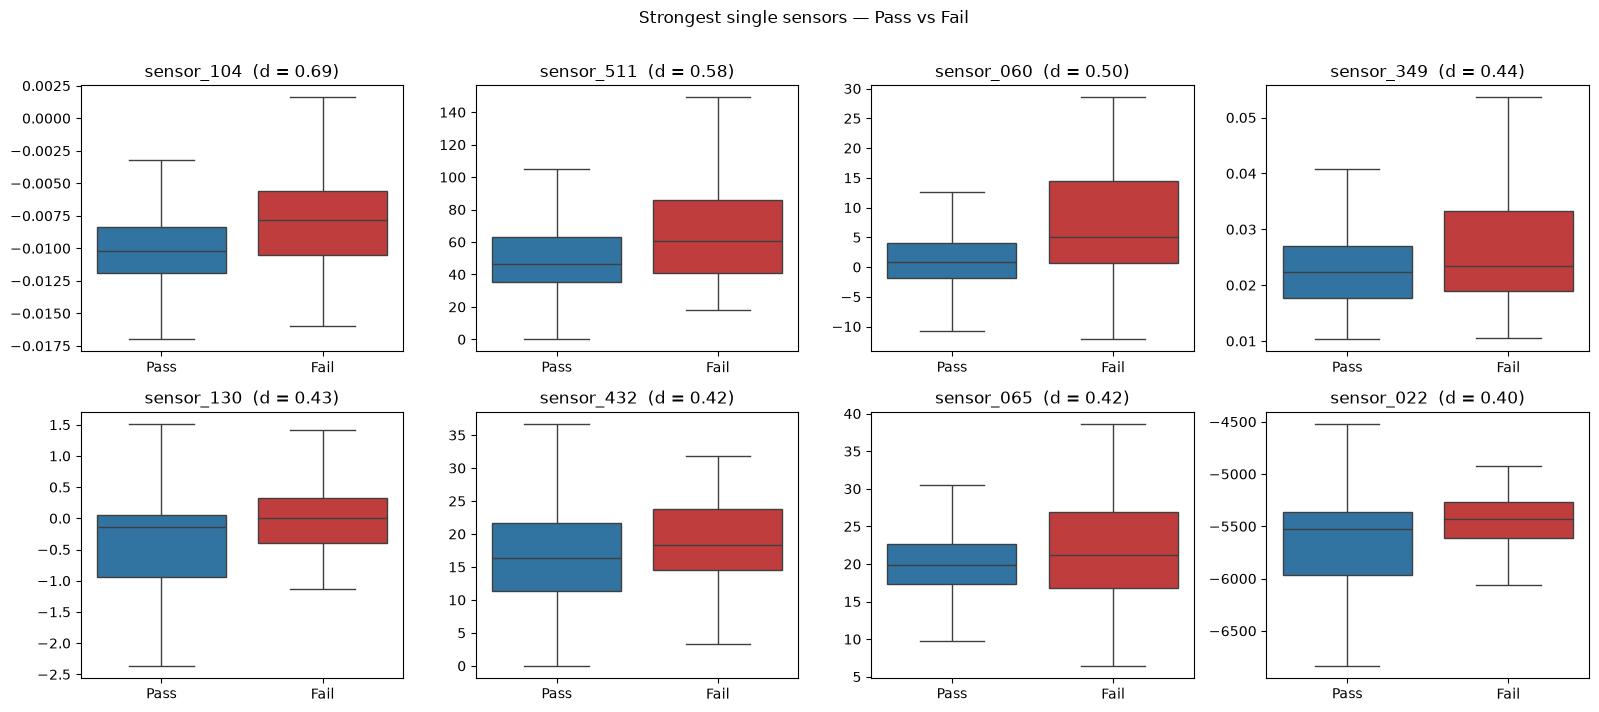

In [11]:
# Only sensors that vary and are at most 50% missing
usable = tr.columns[(tr.nunique() > 1) & (tr.isna().mean() <= 0.5)]

g = tr[usable].groupby(y_train.values)
mean_diff = g.mean().loc[1] - g.mean().loc[0]
effect = (mean_diff / tr[usable].std()).replace([np.inf, -np.inf], np.nan).dropna()

top_effect = effect.abs().sort_values(ascending=False).head(8).index.tolist()
print("Top 8 sensors by |effect size| (Fail vs Pass):")
print(effect[top_effect].round(3).to_string())

cls = y_train.map({0: "Pass", 1: "Fail"}).values
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), top_effect):
    sns.boxplot(x=cls, y=tr[col], hue=cls, legend=False, ax=ax,
                palette={"Pass": "#1f77b4", "Fail": "#d62728"},
                order=["Pass", "Fail"], showfliers=False)
    ax.set_title(f"{col}  (d = {effect[col]:.2f})")
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.suptitle("Strongest single sensors — Pass vs Fail", y=1.01)
plt.tight_layout()
plt.show()

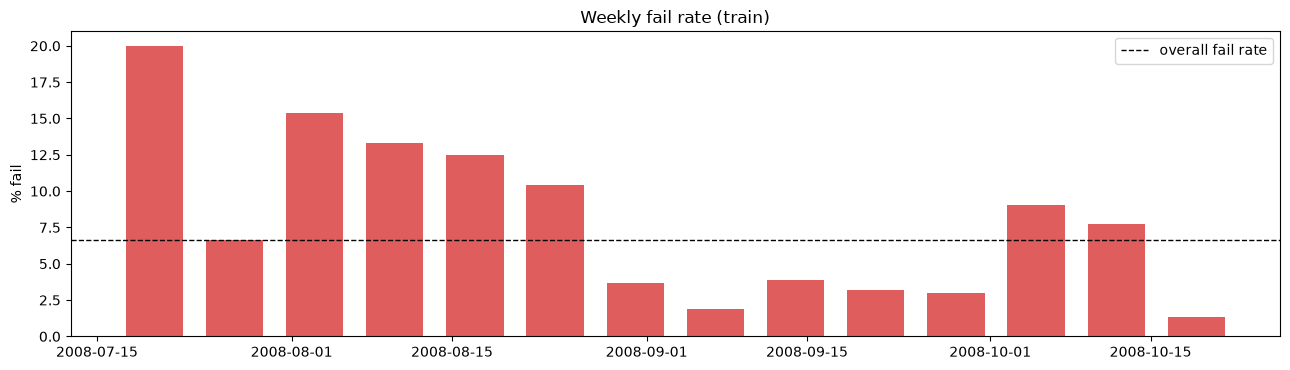

,runs,fails,fail_rate
t,,,
2008-07,47,8,0.170
2008-08,456,41,0.090
2008-09,475,14,0.029
2008-10,275,20,0.073


In [12]:
tl = pd.DataFrame({"t": t_train.values, "fail": y_train.values}).set_index("t").sort_index()
weekly = tl["fail"].resample("W").mean() * 100

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.bar(weekly.index, weekly.values, width=5, color="#d62728", alpha=0.75)
ax.axhline(y_train.mean() * 100, ls="--", c="k", lw=1, label="overall fail rate")
ax.set_title("Weekly fail rate (train)")
ax.set_ylabel("% fail")
ax.legend()
plt.tight_layout()
plt.show()

monthly = tl["fail"].resample("MS").agg(["size", "sum", "mean"])
monthly.index = monthly.index.strftime("%Y-%m")
monthly.columns = ["runs", "fails", "fail_rate"]
monthly.round(3)

In [13]:
n_missing = tr.isna().sum(axis=1)
bins = pd.qcut(n_missing, q=4, duplicates="drop")

print("Fail rate by number of missing sensors per run (quartiles):")
(y_train.groupby(bins, observed=True)
        .agg(["size", "mean"])
        .rename(columns={"size": "runs", "mean": "fail_rate"})
        .round(3))

Fail rate by number of missing sensors per run (quartiles):


,runs,fail_rate
"(3.999, 20.0]",459,0.081
"(20.0, 24.0]",194,0.082
"(24.0, 32.0]",331,0.051
"(32.0, 152.0]",269,0.048


### 4.3 Multivariate analysis — redundancy and structure

Sensors used: 450
Sensor pairs: 101,025
Pairs with |r| > 0.95: 277
Pairs with |r| > 0.80: 608


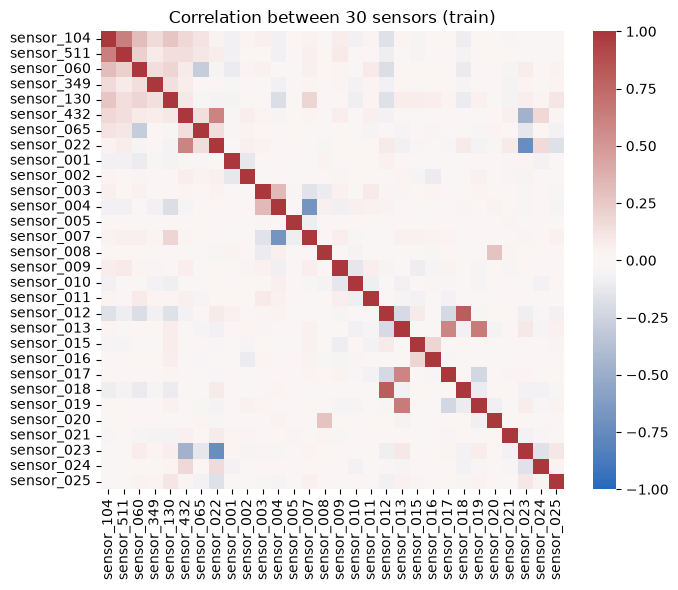

In [14]:
# EDA-only copy: drop constant / mostly-missing sensors, fill gaps, standardise
eda = tr.loc[:, tr.nunique() > 1]
eda = eda.loc[:, eda.isna().mean() <= 0.5]
eda = eda.fillna(eda.median())
eda_z = (eda - eda.mean()) / eda.std()

corr = np.corrcoef(eda_z.to_numpy(), rowvar=False)
upper = np.abs(corr[np.triu_indices_from(corr, k=1)])

print(f"Sensors used: {eda_z.shape[1]}")
print(f"Sensor pairs: {len(upper):,}")
print(f"Pairs with |r| > 0.95: {(upper > 0.95).sum():,}")
print(f"Pairs with |r| > 0.80: {(upper > 0.80).sum():,}")

top30 = top_effect + [c for c in eda_z.columns if c not in top_effect][:22]
plt.figure(figsize=(7, 6))
sns.heatmap(eda_z[top30].corr(), cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Correlation between 30 sensors (train)")
plt.tight_layout()
plt.show()

127 components explain 90% of the variance (out of 450 sensors)


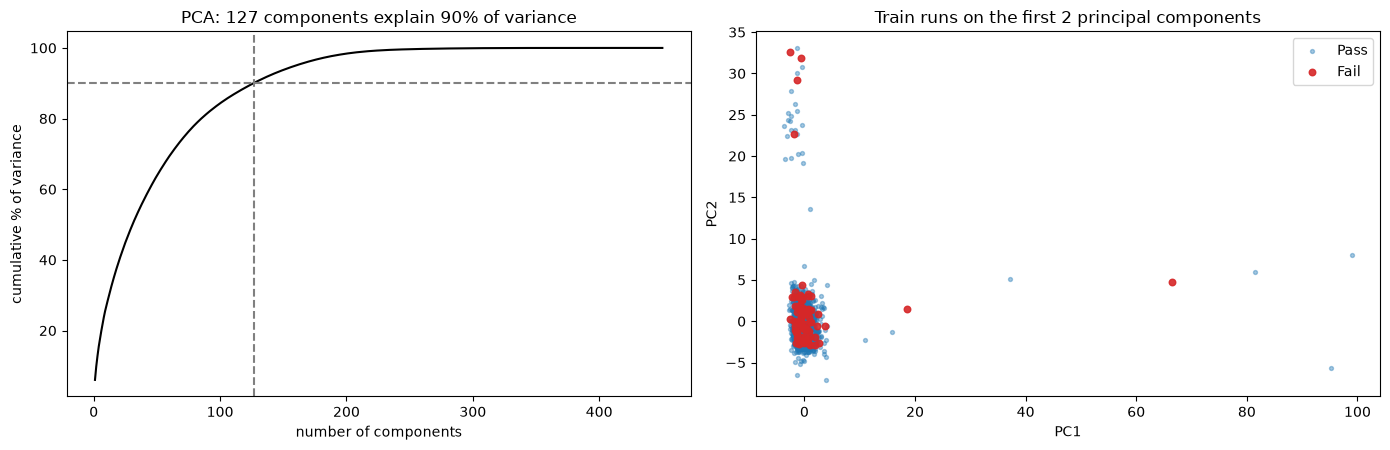

In [15]:
from sklearn.decomposition import PCA

pca_eda = PCA(random_state=SEED).fit(eda_z)
cum = np.cumsum(pca_eda.explained_variance_ratio_)
n90 = int(np.searchsorted(cum, 0.90) + 1)
Z = pca_eda.transform(eda_z)[:, :2]

print(f"{n90} components explain 90% of the variance (out of {eda_z.shape[1]} sensors)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

axes[0].plot(np.arange(1, len(cum) + 1), cum * 100, c="k")
axes[0].axhline(90, ls="--", c="grey")
axes[0].axvline(n90, ls="--", c="grey")
axes[0].set_title(f"PCA: {n90} components explain 90% of variance")
axes[0].set_xlabel("number of components")
axes[0].set_ylabel("cumulative % of variance")

is_pass = y_train.values == 0
axes[1].scatter(Z[is_pass, 0], Z[is_pass, 1], s=8, alpha=0.4, c="#1f77b4", label="Pass")
axes[1].scatter(Z[~is_pass, 0], Z[~is_pass, 1], s=22, alpha=0.9, c="#d62728", label="Fail")
axes[1].set_title("Train runs on the first 2 principal components")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].legend()

plt.tight_layout()
plt.show()

### 4.4 EDA insights → decisions

1. **Severe imbalance.** Only ~6.6% of runs fail (1 : 14). Accuracy is meaningless → use class weights, PR-AUC for model selection and a tuned decision threshold.
2. **Many useless or noisy sensors.** Some sensors are mostly missing or constant, 262 of 590 are strongly skewed (|skew| > 2) and 150 have extreme outliers in > 1% of runs → drop high-missing and constant sensors, clip outliers using training quantiles, impute with the median.
3. **Heavy redundancy.** 277 sensor pairs have |r| > 0.95, and only [N] principal components explain 90% of the variance → reduce dimensions (feature selection or PCA) and drop near-duplicate sensors.
4. **No single sensor separates the classes.** The strongest effect size is only ~0.69 and the Pass/Fail boxplots overlap; fails do not form their own cluster in PC1–PC2 → the signal is weak and spread across many sensors. Because PCA ignores the label, **supervised feature selection may beat PCA**.
5. **The fail rate drifts over time** (17% in July, 3% in September, 7% in October) → a random split may be optimistic; we will also test on a time-ordered split.

## 5 · Preprocessing pipeline (no leakage)

Every step is fitted on the **training data only** (and later on training folds only during cross-validation).

| Step | What it does | Why (from EDA) |
|---|---|---|
| `HighMissingDropper(0.5)` | drop sensors with > 50% missing | too sparse to impute reliably |
| `QuantileClipper(0.5%, 99.5%)` | clip each sensor to training quantiles | controls extreme outliers |
| `SimpleImputer(median)` | fill remaining gaps | median is robust to skew |
| `VarianceThreshold(0)` | drop constant sensors | carry no information |
| `CorrelationFilter(0.95)` | drop near-duplicate sensors | removes redundancy |
| `StandardScaler` | zero mean, unit variance | needed by logistic regression, SVM and PCA |

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from secom_pipeline import HighMissingDropper, QuantileClipper, CorrelationFilter

def make_prep():
    return [
        ("drop_missing",    HighMissingDropper(threshold=0.5)),
        ("clip_outliers",   QuantileClipper(lower=0.005, upper=0.995)),
        ("impute",          SimpleImputer(strategy="median")),
        ("drop_constant",   VarianceThreshold(threshold=0.0)),
        ("drop_correlated", CorrelationFilter(threshold=0.95)),
        ("scale",           StandardScaler()),
    ]

prep = Pipeline(make_prep()).set_output(transform="pandas")
X_train_prep = prep.fit_transform(X_train, y_train)   # learn from train
X_test_prep  = prep.transform(X_test)                 # only apply to test

steps = prep.named_steps
print(f"Start:                        {X_train.shape[1]} sensors")
print(f"After dropping >50% missing:  {len(steps['drop_missing'].columns_out_)}")
print(f"After dropping constant:      {int(steps['drop_constant'].get_support().sum())}")
print(f"After correlation filter:     {len(steps['drop_correlated'].columns_out_)}")
print("Train after prep:", X_train_prep.shape, "| Test after prep:", X_test_prep.shape)
print("Missing values left in test:", int(X_test_prep.isna().sum().sum()))

Start:                        590 sensors
After dropping >50% missing:  566
After dropping constant:      444
After correlation filter:     273
Train after prep: (1253, 273) | Test after prep: (314, 273)
Missing values left in test: 0


## 6 · Modeling — baseline + 4 algorithms × 2 reduction branches

All models use **class weights** for the imbalance. Each one is tried with **feature selection** (`SelectKBest`) and with **PCA**, using default settings and **5-fold stratified cross-validation on the training set only**.

In [17]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone

def make_pipe(clf, branch="fs"):
    """Full pipeline: preprocessing → reduction (feature selection or PCA) → model."""
    if branch == "fs":
        reduce = SelectKBest(f_classif, k=40)
    else:
        reduce = PCA(n_components=0.90, random_state=SEED)
    steps = make_prep() + [("reduce", reduce), ("clf", clf)]
    return Pipeline(steps).set_output(transform="pandas")

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc"}

ALGOS = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=5000),
    "SVM (RBF)":           SVC(kernel="rbf", class_weight="balanced"),
    "Random Forest":       RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                                  n_jobs=-1, random_state=SEED),
    "Gradient Boosting":   HistGradientBoostingClassifier(class_weight="balanced", early_stopping=False,
                                                          random_state=SEED),
}

In [19]:
import time

rows = []

# Baseline
base = cross_validate(DummyClassifier(strategy="prior"), X_train, y_train, cv=cv, scoring=SCORING)
rows.append({"model": "Baseline (prior)", "branch": "-",
             "cv_pr_auc": base["test_pr_auc"].mean(), "cv_pr_auc_std": base["test_pr_auc"].std(),
             "cv_roc_auc": base["test_roc_auc"].mean()})

# 4 algorithms × 2 branches
t0 = time.time()
for name, clf in ALGOS.items():
    for branch in ["fs", "pca"]:
        res = cross_validate(make_pipe(clone(clf), branch), X_train, y_train,
                             cv=cv, scoring=SCORING, n_jobs=-1)
        rows.append({"model": name,
                     "branch": "Feature selection" if branch == "fs" else "PCA",
                     "cv_pr_auc": res["test_pr_auc"].mean(),
                     "cv_pr_auc_std": res["test_pr_auc"].std(),
                     "cv_roc_auc": res["test_roc_auc"].mean()})
        print(f"{name:20s} {branch:3s} → CV PR-AUC {rows[-1]['cv_pr_auc']:.3f}  ({time.time() - t0:.0f}s)")

default_results = pd.DataFrame(rows).round(3)
default_results

Logistic Regression  fs  → CV PR-AUC 0.190  (4s)
Logistic Regression  pca → CV PR-AUC 0.161  (7s)
SVM (RBF)            fs  → CV PR-AUC 0.152  (10s)
SVM (RBF)            pca → CV PR-AUC 0.210  (13s)
Random Forest        fs  → CV PR-AUC 0.207  (15s)
Random Forest        pca → CV PR-AUC 0.114  (16s)
Gradient Boosting    fs  → CV PR-AUC 0.192  (19s)
Gradient Boosting    pca → CV PR-AUC 0.137  (29s)


,model,branch,cv_pr_auc,cv_pr_auc_std,cv_roc_auc
0,Baseline (prior),-,0.066,0.002,0.500
1,Logistic Regression,Feature selection,0.190,0.054,0.666
2,Logistic Regression,PCA,0.161,0.048,0.633
3,SVM (RBF),Feature selection,0.152,0.035,0.670
4,SVM (RBF),PCA,0.210,0.079,0.682
5,Random Forest,Feature selection,0.207,0.052,0.720
6,Random Forest,PCA,0.114,0.030,0.580
7,Gradient Boosting,Feature selection,0.192,0.039,0.654
8,Gradient Boosting,PCA,0.137,0.032,0.586


## 7 · Hyperparameter tuning & cross-validation (training data only)

Grid search with the same 5-fold stratified CV, optimising **PR-AUC**. The number of selected sensors `k` (or PCA components) is tuned together with each model's own hyperparameters.

In [20]:
GRIDS = {
    "Logistic Regression": {"clf__C": [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.1]},
    "SVM (RBF)":           {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.001]},
    "Random Forest":       {"clf__max_depth": [4, 8], "clf__min_samples_leaf": [1, 5]},
    "Gradient Boosting":   {"clf__learning_rate": [0.03, 0.1], "clf__max_depth": [2, 3],
                            "clf__max_iter": [100, 300]},
}
REDUCE_GRID = {
    "fs":  {"reduce__k": [20, 40, 80]},
    "pca": {"reduce__n_components": [10, 30, 0.90]},
}

n_fits = sum(np.prod([len(v) for v in {**g, **REDUCE_GRID[b]}.values()])
             for g in GRIDS.values() for b in REDUCE_GRID) * cv.get_n_splits()
print("Total model fits:", n_fits)

Total model fits: 720


In [21]:
from sklearn.model_selection import GridSearchCV

searches, rows = {}, []
t0 = time.time()
for name, clf in ALGOS.items():
    for branch in ["fs", "pca"]:
        grid = {**GRIDS[name], **REDUCE_GRID[branch]}
        gs = GridSearchCV(make_pipe(clone(clf), branch), grid,
                          scoring=SCORING, refit="pr_auc", cv=cv, n_jobs=-1)
        gs.fit(X_train, y_train)
        searches[(name, branch)] = gs

        i = gs.best_index_
        rows.append({
            "model": name,
            "branch": "Feature selection" if branch == "fs" else "PCA",
            "cv_pr_auc":     gs.cv_results_["mean_test_pr_auc"][i],
            "cv_pr_auc_std": gs.cv_results_["std_test_pr_auc"][i],
            "cv_roc_auc":    gs.cv_results_["mean_test_roc_auc"][i],
            "best_params":   {k.split("__")[1]: v for k, v in gs.best_params_.items()},
        })
        print(f"{name:20s} {branch:3s} → CV PR-AUC {rows[-1]['cv_pr_auc']:.3f}  ({time.time() - t0:.0f}s)")

tuned = pd.DataFrame(rows).sort_values("cv_pr_auc", ascending=False).reset_index(drop=True)
tuned.round(3)

Logistic Regression  fs  → CV PR-AUC 0.209  (6s)
Logistic Regression  pca → CV PR-AUC 0.215  (12s)
SVM (RBF)            fs  → CV PR-AUC 0.214  (19s)
SVM (RBF)            pca → CV PR-AUC 0.210  (25s)
Random Forest        fs  → CV PR-AUC 0.223  (34s)
Random Forest        pca → CV PR-AUC 0.175  (43s)
Gradient Boosting    fs  → CV PR-AUC 0.195  (86s)
Gradient Boosting    pca → CV PR-AUC 0.157  (145s)


,model,branch,cv_pr_auc,cv_pr_auc_std,cv_roc_auc,best_params
0,Random Forest,Feature selection,0.223,0.055,0.710,"{'max_depth': 4, 'min_samples_leaf': 1, 'k': 80}"
1,Logistic Regression,PCA,0.215,0.096,0.692,"{'C': 0.001, 'n_components': 0.9}"
2,SVM (RBF),Feature selection,0.214,0.082,0.707,"{'C': 0.1, 'gamma': 'scale', 'k': 20}"
3,SVM (RBF),PCA,0.210,0.079,0.682,"{'C': 1, 'gamma': 'scale', 'n_components': 0.9}"
4,Logistic Regression,Feature selection,0.209,0.087,0.693,"{'C': 0.0003, 'k': 40}"
5,Gradient Boosting,Feature selection,0.195,0.073,0.667,"{'learning_rate': 0.03, 'max_depth': 2, 'max_i..."
6,Random Forest,PCA,0.175,0.078,0.599,"{'max_depth': 4, 'min_samples_leaf': 5, 'n_com..."
7,Gradient Boosting,PCA,0.157,0.045,0.633,"{'learning_rate': 0.1, 'max_depth': 2, 'max_it..."


branch,Feature selection,PCA,winner
model,,,
Gradient Boosting,0.195,0.157,Feature selection
Logistic Regression,0.209,0.215,PCA
Random Forest,0.223,0.175,Feature selection
SVM (RBF),0.214,0.210,Feature selection


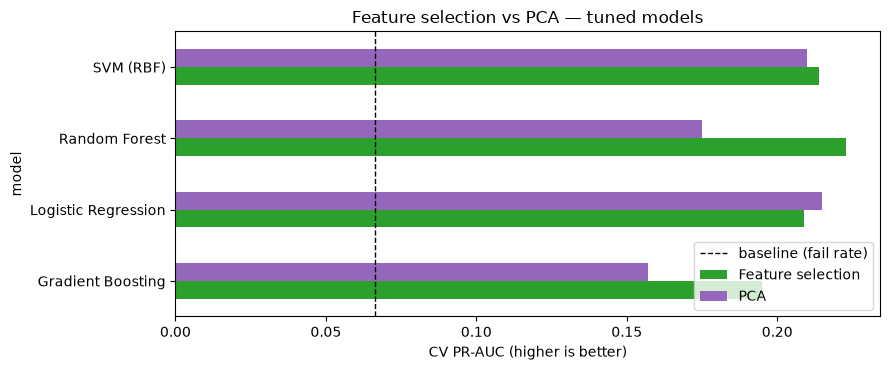

In [22]:
cmp = tuned.pivot(index="model", columns="branch", values="cv_pr_auc").round(3)
cmp["winner"] = np.where(cmp["Feature selection"] >= cmp["PCA"], "Feature selection", "PCA")
display(cmp)

ax = cmp[["Feature selection", "PCA"]].plot.barh(figsize=(9, 3.8), color=["#2ca02c", "#9467bd"])
ax.axvline(y_train.mean(), ls="--", c="k", lw=1, label="baseline (fail rate)")
ax.set_xlabel("CV PR-AUC (higher is better)")
ax.set_title("Feature selection vs PCA — tuned models")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Model choice rule (decided before looking at the test set):** engineers need to know *which sensors* drive failures, and the app must show them, so the deployed model must keep real sensors → we deploy the **best feature-selection model by CV PR-AUC**, after checking that the best PCA model is not clearly better (difference larger than the CV standard deviation).

In [23]:
best_fs  = tuned[tuned.branch == "Feature selection"].iloc[0]
best_pca = tuned[tuned.branch == "PCA"].iloc[0]
print(f"Best feature-selection model: {best_fs.model:20s} CV PR-AUC {best_fs.cv_pr_auc:.3f} ± {best_fs.cv_pr_auc_std:.3f}")
print(f"Best PCA model:               {best_pca.model:20s} CV PR-AUC {best_pca.cv_pr_auc:.3f} ± {best_pca.cv_pr_auc_std:.3f}")

best_name   = best_fs.model
best_search = searches[(best_name, "fs")]
final_pipe  = clone(best_search.best_estimator_)

if isinstance(final_pipe.named_steps["clf"], SVC):   # the app needs probabilities
    final_pipe.set_params(clf__probability=True, clf__random_state=SEED)

print("\nDeployed configuration:", best_name, best_search.best_params_)

Best feature-selection model: Random Forest        CV PR-AUC 0.223 ± 0.055
Best PCA model:               Logistic Regression  CV PR-AUC 0.215 ± 0.096

Deployed configuration: Random Forest {'clf__max_depth': 4, 'clf__min_samples_leaf': 1, 'reduce__k': 80}


## 8 · Choosing the decision threshold (training data only)

The default 0.5 is arbitrary for an imbalanced problem. We get **out-of-fold probabilities** for every training run (each run is scored by a model that never saw it) and pick the threshold that maximises **F2** (recall weighted twice as much as precision, because a missed fail costs more than an extra inspection).

Out-of-fold PR-AUC (train): 0.190
Chosen threshold: 0.283
  → OOF recall 0.72 | precision 0.11 | F2 0.34
Share of runs that would be flagged: 43.4%


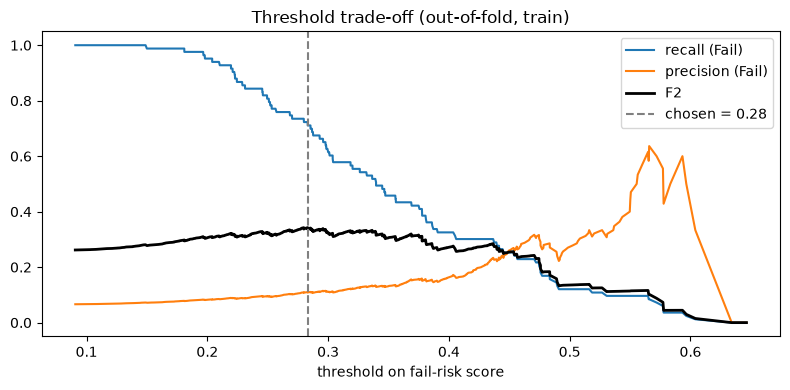

In [24]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, average_precision_score

oof = cross_val_predict(final_pipe, X_train, y_train, cv=cv,
                        method="predict_proba", n_jobs=-1)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)
f2 = (5 * prec * rec) / (4 * prec + rec + 1e-12)
best_i = int(np.nanargmax(f2[:-1]))
THRESHOLD = float(thr[best_i])

print(f"Out-of-fold PR-AUC (train): {average_precision_score(y_train, oof):.3f}")
print(f"Chosen threshold: {THRESHOLD:.3f}")
print(f"  → OOF recall {rec[best_i]:.2f} | precision {prec[best_i]:.2f} | F2 {f2[best_i]:.2f}")
print(f"Share of runs that would be flagged: {(oof >= THRESHOLD).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thr, rec[:-1], label="recall (Fail)")
ax.plot(thr, prec[:-1], label="precision (Fail)")
ax.plot(thr, f2[:-1], label="F2", lw=2, c="k")
ax.axvline(THRESHOLD, ls="--", c="grey", label=f"chosen = {THRESHOLD:.2f}")
ax.set_xlabel("threshold on fail-risk score")
ax.set_title("Threshold trade-off (out-of-fold, train)")
ax.legend()
plt.tight_layout()
plt.show()

## 9 · Final evaluation on the untouched test set

The chosen pipeline is fitted on the **whole training set** and the test set is scored **once**. The model, its settings and the threshold were all fixed before this point.

In [25]:
from sklearn.metrics import (roc_auc_score, precision_score, recall_score, f1_score,
                             fbeta_score, classification_report)

final_pipe.fit(X_train, y_train)
p_test = final_pipe.predict_proba(X_test)[:, 1]
yhat = (p_test >= THRESHOLD).astype(int)

test_metrics = {
    "PR-AUC":           average_precision_score(y_test, p_test),
    "ROC-AUC":          roc_auc_score(y_test, p_test),
    "Recall (Fail)":    recall_score(y_test, yhat),
    "Precision (Fail)": precision_score(y_test, yhat, zero_division=0),
    "F1 (Fail)":        f1_score(y_test, yhat),
    "F2 (Fail)":        fbeta_score(y_test, yhat, beta=2),
    "Flagged runs %":   yhat.mean() * 100,
}
baseline_metrics = {"PR-AUC": y_test.mean(), "ROC-AUC": 0.5, "Recall (Fail)": 0.0,
                    "Precision (Fail)": 0.0, "F1 (Fail)": 0.0, "F2 (Fail)": 0.0,
                    "Flagged runs %": 0.0}

# Bootstrap 95% CI
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].sum() == 0:
        continue
    boot.append((average_precision_score(yt[idx], p_test[idx]),
                 roc_auc_score(yt[idx], p_test[idx])))
boot = np.array(boot)
ci = {"PR-AUC":  np.percentile(boot[:, 0], [2.5, 97.5]),
      "ROC-AUC": np.percentile(boot[:, 1], [2.5, 97.5])}

results_table = pd.DataFrame({"Baseline": baseline_metrics, best_name: test_metrics}).round(3)
display(results_table)
print(f"95% bootstrap CI — PR-AUC [{ci['PR-AUC'][0]:.3f}, {ci['PR-AUC'][1]:.3f}] | "
      f"ROC-AUC [{ci['ROC-AUC'][0]:.3f}, {ci['ROC-AUC'][1]:.3f}]\n")
print(classification_report(y_test, yhat, target_names=["Pass", "Fail"], digits=3))

,Baseline,Random Forest
PR-AUC,0.067,0.240
ROC-AUC,0.500,0.813
Recall (Fail),0.000,0.905
Precision (Fail),0.000,0.120
F1 (Fail),0.000,0.212
F2 (Fail),0.000,0.393
Flagged runs %,0.000,50.318


95% bootstrap CI — PR-AUC [0.141, 0.421] | ROC-AUC [0.702, 0.907]

              precision    recall  f1-score   support

        Pass      0.987     0.526     0.686       293
        Fail      0.120     0.905     0.212        21

    accuracy                          0.551       314
   macro avg      0.554     0.715     0.449       314
weighted avg      0.929     0.551     0.654       314



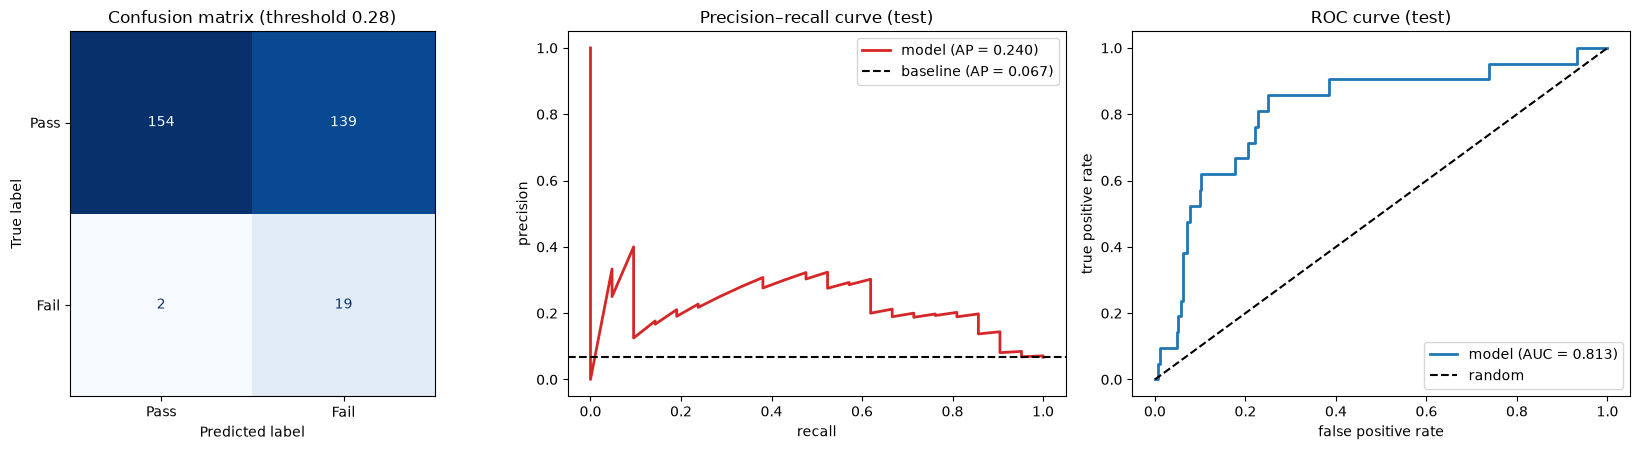

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

# 1) Confusion matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, yhat), display_labels=["Pass", "Fail"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion matrix (threshold {THRESHOLD:.2f})")

# 2) Precision–recall curve
pr, rc, _ = precision_recall_curve(y_test, p_test)
axes[1].plot(rc, pr, c="#d62728", lw=2, label=f"model (AP = {test_metrics['PR-AUC']:.3f})")
axes[1].axhline(y_test.mean(), ls="--", c="k", label=f"baseline (AP = {y_test.mean():.3f})")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision–recall curve (test)")
axes[1].legend()

# 3) ROC curve
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[2].plot(fpr, tpr, c="#1f77b4", lw=2, label=f"model (AUC = {test_metrics['ROC-AUC']:.3f})")
axes[2].plot([0, 1], [0, 1], ls="--", c="k", label="random")
axes[2].set_xlabel("false positive rate")
axes[2].set_ylabel("true positive rate")
axes[2].set_title("ROC curve (test)")
axes[2].legend()

plt.tight_layout()
plt.show()

### 9.1 Error analysis

outcome
correct pass (TN)    154
false alarm (FP)     139
caught fail (TP)      19
missed fail (FN)       2 



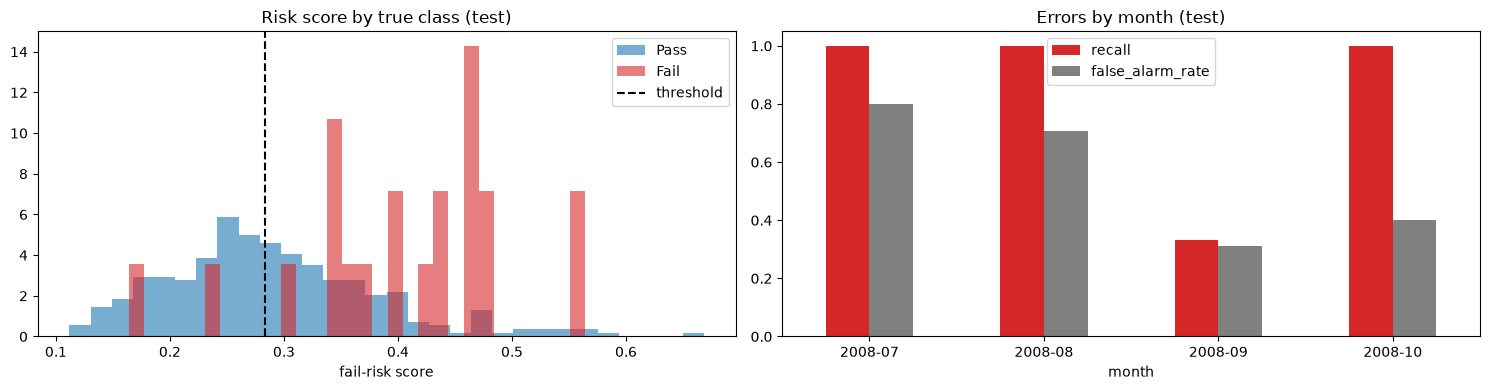

         runs  fails  recall  false_alarm_rate
month                                         
2008-07    16      6   1.000             0.800
2008-08    99     10   1.000             0.708
2008-09   115      3   0.333             0.312
2008-10    84      2   1.000             0.402 

Missed fails:
               timestamp  p_fail
1189 2008-09-30 02:44:00   0.164
795  2008-09-11 22:07:00   0.231


In [27]:
err = pd.DataFrame({"timestamp": t_test.values, "true": y_test.values,
                    "p_fail": p_test, "pred": yhat}, index=X_test.index)
err["outcome"] = np.select(
    [(err.true == 1) & (err.pred == 1),
     (err.true == 1) & (err.pred == 0),
     (err.true == 0) & (err.pred == 1)],
    ["caught fail (TP)", "missed fail (FN)", "false alarm (FP)"],
    default="correct pass (TN)")
print(err.outcome.value_counts().to_string(), "\n")

err["month"] = err.timestamp.dt.strftime("%Y-%m")
by_month = pd.DataFrame({
    "runs":             err.groupby("month").size(),
    "fails":            err.groupby("month")["true"].sum(),
    "recall":           err[err.true == 1].groupby("month")["pred"].mean(),
    "false_alarm_rate": err[err.true == 0].groupby("month")["pred"].mean(),
})

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for lab, color, name in [(0, "#1f77b4", "Pass"), (1, "#d62728", "Fail")]:
    axes[0].hist(err.loc[err.true == lab, "p_fail"], bins=30, alpha=0.6,
                 color=color, label=name, density=True)
axes[0].axvline(THRESHOLD, ls="--", c="k", label="threshold")
axes[0].set_title("Risk score by true class (test)")
axes[0].set_xlabel("fail-risk score")
axes[0].legend()

by_month[["recall", "false_alarm_rate"]].plot.bar(ax=axes[1], color=["#d62728", "grey"])
axes[1].set_title("Errors by month (test)")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print(by_month.round(3), "\n")
print("Missed fails:")
missed = err[err.outcome == "missed fail (FN)"][["timestamp", "p_fail"]].copy()
missed["p_fail"] = missed["p_fail"].round(3)
print(missed.to_string())

In [28]:
order = df.sort_values("timestamp").index
cut = int(len(order) * 0.8)
tr_idx, te_idx = order[:cut], order[cut:]

time_pipe = clone(final_pipe).fit(X.loc[tr_idx], y.loc[tr_idx])
p_time = time_pipe.predict_proba(X.loc[te_idx])[:, 1]
y_time = y.loc[te_idx]
yhat_time = (p_time >= THRESHOLD).astype(int)

print(f"Time split — train: {df.timestamp[tr_idx].min():%Y-%m-%d} → {df.timestamp[tr_idx].max():%Y-%m-%d} "
      f"(fail rate {y.loc[tr_idx].mean():.1%})")
print(f"             test:  {df.timestamp[te_idx].min():%Y-%m-%d} → {df.timestamp[te_idx].max():%Y-%m-%d} "
      f"(fail rate {y_time.mean():.1%}, {int(y_time.sum())} fails)\n")
print(f"PR-AUC  {average_precision_score(y_time, p_time):.3f}  (baseline {y_time.mean():.3f})")
print(f"ROC-AUC {roc_auc_score(y_time, p_time):.3f}")
print(f"Recall at our threshold: {recall_score(y_time, yhat_time):.2f} | flagged {yhat_time.mean():.1%}")

Time split — train: 2008-07-19 → 2008-10-02 (fail rate 6.9%)
             test:  2008-10-02 → 2008-10-17 (fail rate 5.4%, 17 fails)

PR-AUC  0.092  (baseline 0.054)
ROC-AUC 0.651
Recall at our threshold: 0.47 | flagged 30.3%


**What the error analysis tells us**
- **Fails caught:** 19 of 21 test fails (recall 90%), at the cost of flagging 50% of runs (139 false alarms). Inspecting the same share of runs at random would catch about 10–11 fails.
- **Missed fails:** both are from September, with risk scores 0.164 and 0.231 (threshold 0.283) — they look like normal runs on the sensors the model uses, so their cause is probably not captured by the recorded signals.
- **False alarms depend on the period:** 80% of good runs in July and 71% in August were flagged, vs 31–40% in September–October. The fail rate was highest early in the period, so the model partly learned period-specific patterns — an effect of process drift.
- **Uncertainty is large:** with only 21 test fails, the 95% bootstrap CI is 0.14–0.42 for PR-AUC and 0.70–0.91 for ROC-AUC.
- **Future runs are harder:** trained on the earliest 80% of runs and tested on the latest 20%, the model reaches PR-AUC 0.092 (baseline 0.054), ROC-AUC 0.651 and recall 0.47 at the same threshold. In production the model must be **retrained regularly** and its threshold re-checked.

### 9.2 Post-hoc check: wider tuning grid (training data only)

The first grid search picked values at the edge of the grid (`k = 80`, `max_depth = 4`). After the test evaluation we noticed this, so we test a wider grid with the **same 5-fold CV on the training set only** — the test set is not used here.
**Decision rule, fixed before running:** adopt the new settings only if the CV PR-AUC gain is larger than the CV standard deviation; otherwise keep the current, simpler model.

In [29]:
grid_ext = {
    "clf__max_depth":        [2, 3, 4],
    "clf__min_samples_leaf": [1, 3],
    "clf__n_estimators":     [200, 500],
    "reduce__k":             [80, 120, 160],
}
gs_ext = GridSearchCV(make_pipe(clone(ALGOS["Random Forest"]), "fs"), grid_ext,
                      scoring=SCORING, refit="pr_auc", cv=cv, n_jobs=-1)
gs_ext.fit(X_train, y_train)

i = gs_ext.best_index_
print(f"Current model:  CV PR-AUC {best_fs.cv_pr_auc:.3f} ± {best_fs.cv_pr_auc_std:.3f}")
print(f"Extended grid:  CV PR-AUC {gs_ext.cv_results_['mean_test_pr_auc'][i]:.3f} "
      f"± {gs_ext.cv_results_['std_test_pr_auc'][i]:.3f}")
print("Best params:", gs_ext.best_params_)

Current model:  CV PR-AUC 0.223 ± 0.055
Extended grid:  CV PR-AUC 0.245 ± 0.080
Best params: {'clf__max_depth': 4, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 500, 'reduce__k': 160}


**Result:** wider grid CV PR-AUC 0.245 ± 0.080 vs current model 0.223 ± 0.055.
The gain (0.022) is smaller than the CV standard deviation, the fold-to-fold variability increased, and the best `k` again landed on the edge of the new grid (160) — a sign that performance is flat across `k`, not that a better setting exists.
**Decision: keep the current model** (Random Forest, `k = 80`, `max_depth = 4`, 200 trees).

### 9.3 Post-hoc check: soft-voting ensemble (training data only)

The three best tuned models are close in CV PR-AUC but work very differently (trees on 80 sensors, a linear model on PCA directions, an RBF-SVM on 20 sensors). A **soft-voting ensemble** averages their risk scores; if they make different mistakes, the average can be more stable. Same 5-fold CV on the training set only.
**Decision rule, fixed before running:** adopt the ensemble only if its CV PR-AUC gain over the current model is larger than the CV standard deviation; otherwise keep the single, simpler and more interpretable Random Forest.

In [30]:
from sklearn.ensemble import VotingClassifier

members = [
    ("rf_fs",  clone(searches[("Random Forest", "fs")].best_estimator_)),
    ("lr_pca", clone(searches[("Logistic Regression", "pca")].best_estimator_)),
    ("svm_fs", clone(searches[("SVM (RBF)", "fs")].best_estimator_)
               .set_params(clf__probability=True, clf__random_state=SEED)),
]
ensemble = VotingClassifier(members, voting="soft")

t0 = time.time()
res_ens = cross_validate(ensemble, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
print(f"Done in {time.time() - t0:.0f}s\n")

print(f"Current model (RF):  CV PR-AUC {best_fs.cv_pr_auc:.3f} ± {best_fs.cv_pr_auc_std:.3f} | "
      f"ROC-AUC {best_fs.cv_roc_auc:.3f}")
print(f"Soft-voting ensemble: CV PR-AUC {res_ens['test_pr_auc'].mean():.3f} ± {res_ens['test_pr_auc'].std():.3f} | "
      f"ROC-AUC {res_ens['test_roc_auc'].mean():.3f}")

Done in 2s

Current model (RF):  CV PR-AUC 0.223 ± 0.055 | ROC-AUC 0.710
Soft-voting ensemble: CV PR-AUC 0.240 ± 0.079 | ROC-AUC 0.715


**Result:** soft-voting ensemble CV PR-AUC 0.240 ± 0.079 (ROC-AUC 0.715) vs current model 0.223 ± 0.055 (ROC-AUC 0.710).
The gain (0.017) is smaller than the CV standard deviation, ROC-AUC is practically unchanged, and the fold-to-fold variability **increased** — the three models tend to miss the same runs, so averaging them does not cancel errors.
**Decision: keep the single Random Forest** (simpler, faster, and directly interpretable).
Together with 9.2, this suggests the remaining limit comes from the **data** (few failures, weak signal, drift), not from the choice of model.

## 10 · Which sensors matter? (stretch goal)

**Permutation importance** on the test set: shuffle one selected sensor at a time and measure the drop in PR-AUC. Only the `k` sensors kept by `SelectKBest` can affect the prediction, so we permute those. No decision is taken from this step — it only explains the final model.

In [31]:
sel = final_pipe.named_steps["reduce"].get_feature_names_out().tolist()
print(f"The model uses {len(sel)} sensors")

def permutation_importance_selected(pipe, X, y, cols, n_repeats=10, seed=SEED):
    """Drop in PR-AUC when each column in `cols` is shuffled (mean and std over repeats)."""
    rng = np.random.default_rng(seed)
    base = average_precision_score(y, pipe.predict_proba(X)[:, 1])
    out = {}
    for c in cols:
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[c] = rng.permutation(Xp[c].to_numpy())
            drops.append(base - average_precision_score(y, pipe.predict_proba(Xp)[:, 1]))
        out[c] = (np.mean(drops), np.std(drops))
    return pd.DataFrame(out, index=["importance", "std"]).T.sort_values("importance", ascending=False)

t0 = time.time()
imp = permutation_importance_selected(final_pipe, X_test, y_test, sel)
print(f"Computed in {time.time() - t0:.0f}s")
top10 = imp.head(10)
top10.round(4)

The model uses 80 sensors
Computed in 43s


,importance,std
sensor_060,0.0545,0.0098
sensor_206,0.0206,0.0070
sensor_248,0.0192,0.0112
sensor_022,0.0169,0.0096
sensor_122,0.0140,0.0052
sensor_065,0.0137,0.0046
sensor_386,0.0092,0.0037
sensor_103,0.0091,0.0058
sensor_131,0.0085,0.0108
sensor_130,0.0083,0.0144


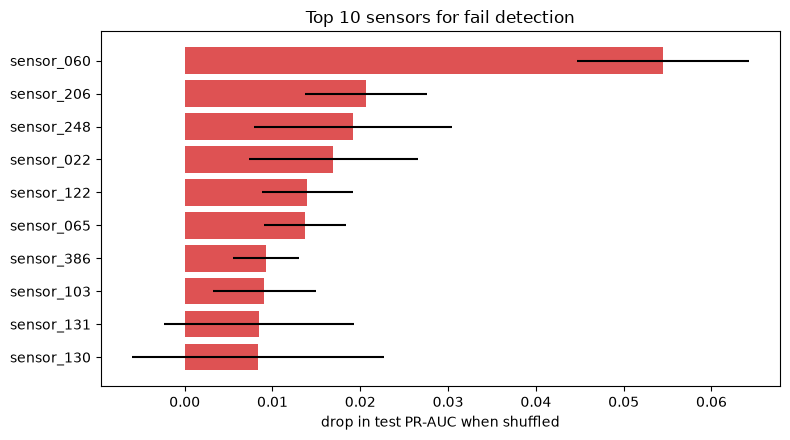

,importance,std,direction,train_missing_pct
sensor_060,0.0545,0.0098,higher in fails,0.4
sensor_206,0.0206,0.0070,higher in fails,0.3
sensor_248,0.0192,0.0112,higher in fails,45.3
sensor_022,0.0169,0.0096,higher in fails,0.1
sensor_122,0.0140,0.0052,higher in fails,0.7
sensor_065,0.0137,0.0046,higher in fails,0.4
sensor_386,0.0092,0.0037,higher in fails,45.3
sensor_103,0.0091,0.0058,lower in fails,0.5
sensor_131,0.0085,0.0108,higher in fails,0.7
sensor_130,0.0083,0.0144,higher in fails,0.7


Also in the EDA top-8 by effect size: ['sensor_022', 'sensor_060', 'sensor_065', 'sensor_130']


In [32]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top10.index[::-1], top10["importance"][::-1], xerr=top10["std"][::-1],
        color="#d62728", alpha=0.8)
ax.set_xlabel("drop in test PR-AUC when shuffled")
ax.set_title("Top 10 sensors for fail detection")
plt.tight_layout()
plt.show()

# Report for the engineering team
diff = (X_train.loc[y_train == 1, top10.index].median()
        - X_train.loc[y_train == 0, top10.index].median())
top10_report = top10.assign(
    direction=np.where(diff > 0, "higher in fails", np.where(diff < 0, "lower in fails", "same median")),
    train_missing_pct=(X_train[top10.index].isna().mean() * 100).round(1),
).round(4)
display(top10_report)

print("Also in the EDA top-8 by effect size:", sorted(set(top10.index) & set(top_effect)))

**Key sensors — what to tell the engineering team**
- **`sensor_060` stands out:** shuffling it drops test PR-AUC by 0.055 ± 0.010 — more than twice any other sensor. Its values are higher in failing runs.
- **Confirmed by two methods:** 4 of the top 10 (`sensor_022`, `sensor_060`, `sensor_065`, `sensor_130`) were also among the strongest single sensors in the EDA effect-size analysis.
- **9 of the top 10 are higher in fails** (only `sensor_103` is lower) — rising readings are the main warning sign.
- **Check data logging:** `sensor_248` and `sensor_386` are both missing in 45.3% of runs (they go missing together), so part of their importance may come from the missing-value pattern itself.
- **Uncertain:** `sensor_130` and `sensor_131` have a standard deviation larger than their importance — treat them as weak candidates.
- Importance shows **association, not cause** — these sensors are where root-cause analysis should start.

## 11 · Business insight

In [33]:
yt_np = y_test.to_numpy()
n_test, n_fail = len(yt_np), int(yt_np.sum())
tp = int(((yhat == 1) & (yt_np == 1)).sum())
fp = int(((yhat == 1) & (yt_np == 0)).sum())
flag_rate = yhat.mean()
random_catch = flag_rate * n_fail

print(f"On {n_test} unseen production runs ({n_fail} real fails), the model flags "
      f"{int(yhat.sum())} runs ({flag_rate:.0%} of production).")
print(f"Those flags catch {tp} of {n_fail} fails (recall {tp / n_fail:.0%}); "
      f"{fp} flagged runs are false alarms (precision {tp / max(yhat.sum(), 1):.0%}).")
print(f"Inspecting the same {flag_rate:.0%} of runs at random would catch about {random_catch:.1f} fails "
      f"→ the model catches {tp / random_catch:.1f}× more.")
print(f"Key sensors to review first: {', '.join(top10.index[:5])}")

On 314 unseen production runs (21 real fails), the model flags 158 runs (50% of production).
Those flags catch 19 of 21 fails (recall 90%); 139 flagged runs are false alarms (precision 12%).
Inspecting the same 50% of runs at random would catch about 10.6 fails → the model catches 1.8× more.
Key sensors to review first: sensor_060, sensor_206, sensor_248, sensor_022, sensor_122


**In plain language**
- The model **cannot replace the final line test**, but it works as an **early-warning filter**: on unseen runs, inspecting the half of production it flags caught 19 of 21 failing runs — about 1.8× more than inspecting the same number of runs at random.
- The **threshold is a business knob**, not a technical constant. A lower threshold catches more fails but sends more good runs to inspection; a higher one does the opposite. The app exposes it as a slider so the quality team can match it to their inspection capacity.
- **`sensor_060`** is the strongest warning signal, followed by `sensor_206`, `sensor_248`, `sensor_022` and `sensor_122`.

**What the factory should do next**
1. **Shadow-mode pilot (4–6 weeks):** score every run, inspect the flagged ones, and compare with the line-test results before relying on the model.
2. **Root-cause review:** process engineers map the top sensors (starting with `sensor_060`) back to their real names and check their control limits and maintenance history.
3. **Fix data logging** for `sensor_248` and `sensor_386`, which are missing in 45% of runs.
4. **Retrain monthly and re-check the threshold:** on future runs (time-ordered test) the model was clearly weaker (PR-AUC 0.092, recall 0.47), because the process drifts.

**Limitations**
- Only **104 failures** in total (21 in the test set) → wide uncertainty on every metric (PR-AUC 95% CI 0.14–0.42).
- **Process drift:** performance drops on future runs; random-split results are optimistic.
- Sensor names are **anonymised**, so findings are associations, not physical explanations — importance is not causation.
- The data come from **one factory in 2008**; results must be re-validated on any other line or period.
- The risk score ranks runs by risk but is **not a calibrated probability**.

## 12 · Save the final pipeline

One bundle with everything the Streamlit app needs: the fitted pipeline, the decision threshold, the selected sensors, their typical (median) values, the importance table and the test results. We also export a small sample of **test** runs for demoing the app, and a `requirements.txt` pinned to the versions used for training.

In [34]:
import sys
import joblib
from pathlib import Path

Path("models").mkdir(exist_ok=True)

bundle = {
    "pipeline":          final_pipe,
    "threshold":         THRESHOLD,
    "model_name":        best_name,
    "best_params":       best_search.best_params_,
    "selected_sensors":  sel,
    "baseline_values":   X_train[sel].median().to_dict(),
    "sensor_importance": imp.reset_index(names="sensor").to_dict("records"),
    "test_metrics":      {k: float(v) for k, v in test_metrics.items()},
    "test_ci":           {k: [float(a), float(b)] for k, (a, b) in ci.items()},
    "train_fail_rate":   float(y_train.mean()),
    "n_train":           int(len(y_train)),
    "n_test":            int(len(y_test)),
    "versions": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__},
}
joblib.dump(bundle, "models/secom_fail_detector.joblib", compress=3)
print("Saved models/secom_fail_detector.joblib")
print("Versions:", bundle["versions"])

Saved models/secom_fail_detector.joblib
Versions: {'python': '3.12.7', 'scikit-learn': '1.9.1', 'pandas': '3.1.0', 'numpy': '2.5.4'}


In [35]:
Path("sample_data").mkdir(exist_ok=True)

demo = pd.concat([X_test[y_test == 1].head(10),
                  X_test[y_test == 0].head(15)]).sample(frac=1, random_state=SEED)
demo.insert(0, "run_id", [f"RUN-{i:04d}" for i in demo.index])
demo.insert(1, "label", y_test.loc[demo.index].to_numpy())
demo.to_csv("sample_data/sample_runs.csv", index=False)

print("Saved sample_data/sample_runs.csv:", demo.shape,
      f"({int(demo['label'].sum())} fails, {int((demo['label'] == 0).sum())} passes)")

Saved sample_data/sample_runs.csv: (25, 592) (10 fails, 15 passes)


In [36]:
import matplotlib, seaborn, streamlit

requirements = [
    f"streamlit=={streamlit.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"pandas=={pd.__version__}",
    f"numpy=={np.__version__}",
    f"joblib=={joblib.__version__}",
    f"matplotlib=={matplotlib.__version__}",
    f"seaborn=={seaborn.__version__}",
]
Path("requirements.txt").write_text("\n".join(requirements) + "\n")
print(Path("requirements.txt").read_text())
print(f"Python used: {sys.version.split()[0]}  ← choose the same version on Streamlit Cloud")

streamlit==1.66.1
scikit-learn==1.9.1
pandas==3.1.0
numpy==2.5.4
joblib==1.6.0
matplotlib==3.11.2
seaborn==0.13.2

Python used: 3.12.7  ← choose the same version on Streamlit Cloud


In [37]:
reloaded = joblib.load("models/secom_fail_detector.joblib")
p_reloaded = reloaded["pipeline"].predict_proba(X_test)[:, 1]

assert np.allclose(p_reloaded, p_test), "Reloaded model gives different predictions!"
print("Reload check passed ✔ — same predictions as the trained model")
print("Threshold:", round(reloaded["threshold"], 3), "| sensors:", len(reloaded["selected_sensors"]))

Reload check passed ✔ — same predictions as the trained model
Threshold: 0.283 | sensors: 80
